# Kikuchi asymmetry — long-range figure

Long-range sweeps (±2.5°). Same corrected metric, layout and styling as
`create_paper_figs_kikuchi_short_range.ipynb`.

**Data**

- **PTO: job 58325574 export** (81 tilts, zone axis [1,0,0], 40 phonons). The previous
  `long_range/PTO_long_range_kikuchi_asymmetry_data.npz` was run down **[010]** (aperture ratio
  0.9858), which puts the polar *c*-axis on the wrong array axis, so it is not used. The export
  ships the corrected metric per tilt (`metrics.csv`), pixel strips and an 8×-binned preview
  rather than full patterns; see `from_export` below.
- **BTO** (80 tilts, [100], ratio 1.0083) and **boracite** (81 tilts) from `data/long_range/`,
  streamed from the 10 GB NPZs and cached in `cache_longrange/`.

**Changed from the previous version of this notebook:** corrected `masked_com` instead of the
midpoint metric, exact `N+1-hi` mirror, top-third box dropped, reciprocal-space calibration,
`paper` stylesheet. The 20- vs 40-phonon BTO comparison cells were removed (they sat behind a
`sys.exit()` and used the old metric).

In [1]:
import os
import io
import sys
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LogNorm

plt.style.use("paper")   # ~/.config/matplotlib/stylelib

sys.path.insert(0, "..")
from polarisation_direction import P_REVERSED
from kikuchi_com import FULL_BOX, BORACITE_EXTENT, angular_box, mirror_box, masked_com, stream_patterns

# ── Electron wavelength and per-material reciprocal calibration ──────────────
# mrad per detector pixel = lambda / (in-plane supercell extent); see the
# short-range notebook for the cross-check against the PTO Bragg spacing.
_h, _m, _e, _c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
LAMBDA = _h / np.sqrt(2*_m*_e*300e3) / np.sqrt(1 + _e*300e3/(2*_m*_c**2)) * 1e10  # 0.019687 A

N = 4096
FOV_MRAD   = 215.0   # half-width shown, same as the short-range figure
SCALEBAR   = 4.0     # inverse angstrom
TILT_SIGN  = -1      # x-axis convention, tilt axis only, identical for every row

EXPORT = ("../data/long_range_export/PTO_long_range_tilt_split_job58325574_export/"
          "PTO_long_range_tilt_split_job58325574_")

# BTO's CIF is polarised opposite to PTO's, so it is mirrored: y_aligned(t) = -y(-t).
# See the short-range notebook for the derivation.
MATERIALS = {
    "PTO": dict(
        formula=r"PbTiO$_3$", abbr="PTO", export=EXPORT,
        cell=(3.9423, 3.8862), nrep=30),
    "BTO": dict(
        formula=r"BaTiO$_3$", abbr="BTO",
        path="../data/long_range/BTO_long_range_kikuchi_asymmetry_data.npz",
        cell=(4.0230, 3.9905), nrep=30, flip_polar=True),
    "Boracite": dict(
        formula=r"Cu$_3$B$_7$ClO$_{13}$", abbr="boracite",
        path="../data/long_range/Boracite_long_range_kikuchi_asymmetry_data.npz",
        cell=(17.1032, 17.1032), nrep=7,
        extent=(BORACITE_EXTENT, BORACITE_EXTENT))   # abTEM box, see kikuchi_com,
}
for cfg in MATERIALS.values():
    cfg.setdefault("flip_polar", False)
    a0, a1 = cfg["cell"]; n = cfg["nrep"]
    e0, e1 = cfg.get("extent", (n*a0, n*a1))                      # simulation box (A)
    cfg["mpp"] = (LAMBDA / e0 * 1e3, LAMBDA / e1 * 1e3)           # mrad per px
    cfg["kpp"] = (1.0 / e0,          1.0 / e1)                    # inverse angstrom per px
    cfg.setdefault("box", FULL_BOX)
# Boracite's antialias aperture is at 154 mrad (its larger box gives coarser angular
# pixels), so FULL_BOX's 108-208 mrad is out of reach, and 108-150 mrad sits in the faint
# edge of its pattern. Its box is placed on the bright Kikuchi bands instead, clear of the
# disks (< 35 mrad); same +-10 mrad width as FULL_BOX. The zero-tilt sign is the same for
# every window from 35 to 150 mrad and every width from 2 to 40 mrad, so this choice
# changes the magnitude, not the sign.
MATERIALS["Boracite"]["box"] = angular_box(*MATERIALS["Boracite"]["mpp"], r_mrad=(40.0, 100.0))
for k, cfg in MATERIALS.items():
    b, m = cfg["box"], cfg["mpp"]
    print(f"{k:9s} box {b}  = {(N//2 - b[1] + 1)*m[0]:.1f}-{(N//2 - b[0])*m[0]:.1f} mrad, "
          f"+-{(b[3] - b[2])/2*m[1]:.1f} mrad")

PTO       box (800, 1400, 1988, 2108)  = 108.0-207.7 mrad, +-10.1 mrad
BTO       box (800, 1400, 1988, 2108)  = 105.9-203.6 mrad, +-9.9 mrad
Boracite  box (1188, 1705, 1962, 2134)  = 40.0-100.0 mrad, +-10.0 mrad


In [2]:
CACHE = "cache_longrange"
os.makedirs(CACHE, exist_ok=True)


def tilts(path):
    with zipfile.ZipFile(path).open("tilt_y_values.npy") as h:
        return np.load(io.BytesIO(h.read()))


def from_npz(path, box):
    """Corrected COM on the polar axis, the axis-1 control, and the whole-pattern
    mismatch. One streaming pass over the 10 GB file."""
    t = tilts(path)
    i0 = int(np.argmin(abs(t)))
    box1, box2 = box, mirror_box(box)
    com, ctrl, mism = [], [], []
    for i, p in enumerate(stream_patterns(path)):
        com.append(masked_com(p, box1, box2, 0))
        ctrl.append(masked_com(p, box1, box2, 1))
        # Equal, paired halves: row 0 is the unpaired Nyquist row and row N/2 the
        # centre, so both are excluded. Computed (high - low); negated below.
        lo, hi = p[1:N//2].sum(), p[N//2+1:].sum()
        mism.append((hi - lo) / (hi + lo) * 100)
        if i == i0:
            zero = p.copy()
    return dict(tilt=t, com=np.array(com), ctrl=np.array(ctrl),
                mismatch=np.array(mism), zero=zero, bin=1)


def from_export(prefix):
    """PTO job 58325574 ships the corrected metric per tilt, pixel strips and an
    8x mean-binned preview instead of the full patterns."""
    m = np.genfromtxt(prefix + "metrics.csv", delimiter=",", names=True)
    s = np.load(prefix + "strips.npz")
    pv = np.load(prefix + "preview.npz")
    t = s["tilt_y_deg"]
    assert np.allclose(t, m["tilt_y_deg"])
    b = int(pv["bin_factor"])
    P = pv["preview"].astype(np.float64) * b * b          # mean-binned -> summed counts
    # Whole-pattern mismatch from the binned halves. The low half (rows 0..N/2-1)
    # includes the Nyquist row, which lies outside the antialias aperture and is
    # empty. The high half includes the centre row N/2, which must come out; it is
    # row N/2 - strip_lo of the column strip (pattern[1988:2108, :]).
    centre = s["col_strip"][:, N//2 - int(s["strip_lo"]), :].sum(axis=1)
    lo = P[:, :N//2//b].sum(axis=(1, 2))
    hi = P[:, N//2//b:].sum(axis=(1, 2)) - centre
    return dict(tilt=t, com=m["full_axis0"], ctrl=m["full_axis1"],
                mismatch=(hi - lo) / (hi + lo) * 100,
                zero=P[int(np.argmin(abs(t)))], bin=b)


def process(name, cfg):
    f = os.path.join(CACHE, f"{name}.npz")
    box = tuple(int(v) for v in cfg["box"])
    if os.path.exists(f):
        d = np.load(f)
        # caches written before per-material boxes carry no "box"; those used FULL_BOX
        if (tuple(int(v) for v in d["box"]) if "box" in d.files else FULL_BOX) == box:
            return {k: d[k] for k in d.files}
    if "export" in cfg:
        assert box == FULL_BOX, "the export's metrics.csv was computed with FULL_BOX"
        out = from_export(cfg["export"])
    else:
        out = from_npz(cfg["path"], box)
    out["box"] = np.array(box)
    np.savez_compressed(f, **out)
    return out


results = {k: process(k, cfg) for k, cfg in MATERIALS.items()}

# Sign convention shared with the disk notebooks: POSITIVE = TOP (low row index) BRIGHTER.
# masked_com is + towards higher index and the mismatch was computed (high - low), so
# both are negated here; the cache keeps the raw values.
for r in results.values():
    for key in ("com", "mismatch", "mismatch_ann"):
        if key in r:
            r[key] = -r[key]
for k, r in results.items():
    print(f"{k:9s} n={len(r['tilt'])}  COM {r['com'].min():+8.1f}..{r['com'].max():+8.1f} px")

PTO       n=81  COM   -169.7..  +145.0 px
BTO       n=80  COM   -237.8..  +203.3 px
Boracite  n=81  COM    -93.3..  +109.8 px


### Polarisation signature

A polar offset is **even** in tilt; a purely geometric response is odd and cancels. Array
axis 1 is non-polar, so it acts as a control within the same dataset — it should show no even
component. Quoting an SEM across tilt points would be wrong here: repeat runs show the
tilt-to-tilt structure is deterministic (r = 1.000), not noise.

In [3]:
def even_part(t, y):
    """Even part of y(t) on t > 0, pairing each tilt with its mirror by value.
    BTO is missing +2.1875 deg (80 of 81 tilts), so that one pair is skipped."""
    tp = t[t > 0]
    tp = tp[[np.isclose(t, -x).any() for x in tp]]
    return tp, (np.interp(tp, t, y) + np.interp(-tp, t, y)) / 2


print(f"{'material':9s} {'e_rms polar':>12s} {'e_rms control':>14s} {'ratio':>7s}   (px)")
for k, r in results.items():
    _, ep = even_part(r["tilt"], r["com"])
    _, ec = even_part(r["tilt"], r["ctrl"])
    print(f"{k:9s} {ep.std(ddof=1):12.2f} {ec.std(ddof=1):14.2f} {ep.std(ddof=1)/ec.std(ddof=1):7.1f}")

print(f"\n{'material':9s} {'D0 as simulated':>18s} {'D0 aligned to PTO':>20s}")
for k, r in results.items():
    raw = float(np.interp(0.0, r["tilt"], r["com"])) * MATERIALS[k]["kpp"][0]
    flip = MATERIALS[k]["flip_polar"]
    print(f"{k:9s} {raw:>+13.4f} A^-1 {(-raw if flip else raw):>+15.4f} A^-1"
          f"   {'(flipped)' if flip else ''}")

material   e_rms polar  e_rms control   ratio   (px)
PTO              26.16           0.26   102.4
BTO               8.41           0.29    28.6
Boracite          6.45           1.15     5.6

material     D0 as simulated    D0 aligned to PTO
PTO             -0.2045 A^-1         -0.2045 A^-1   
BTO             +0.0683 A^-1         -0.0683 A^-1   (flipped)
Boracite        -0.0725 A^-1         -0.0725 A^-1   


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved figures/kikuchi_long_range.{pdf,png}


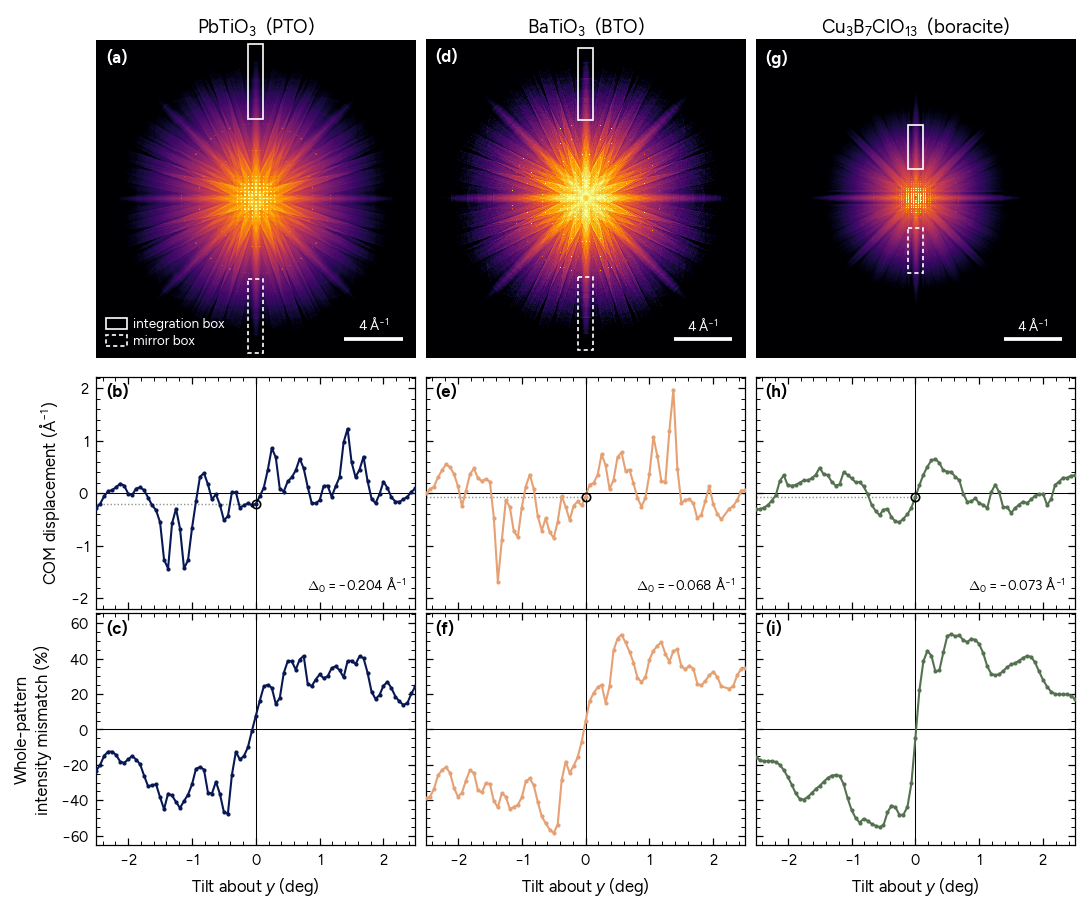

In [4]:
def long_range_figure(raw=False, aligned=False, final=False):
    """raw=True: no polar alignment, tilt as simulated, 'unflipped_' prefix.
    aligned=True: every material mirrored to PTO's polarisation (P_REVERSED), 'aligned_' prefix.
    final=True: common polarisation frame with P towards the TOP box, i.e. PTO mirrored and
    BTO/boracite as simulated (both are built reversed relative to PTO); 'corrected_final/' prefix."""
    pre = "unflipped_" if raw else "aligned_" if aligned else "corrected_final/corrected_final_" if final else ""
    # ── Figure: 180 mm double column, styled by the paper stylesheet (set in cell 1) ───
    MM = 1 / 25.4
    FG, ZERO, GUIDE = "black", "black", "#9a9a96"   # text, zero lines, guide line
    COLOURS = dict(zip(MATERIALS, plt.rcParams["axes.prop_cycle"].by_key()["color"]))

    fig, axes = plt.subplots(
        3, 3, figsize=(180*MM, 150*MM),
        gridspec_kw={"height_ratios": [1.5, 1.0, 1.0]},
        layout="constrained",
    )
    fig.get_layout_engine().set(h_pad=0.01, w_pad=0.01, hspace=0.015, wspace=0.03)

    letters = iter("abcdefghi")

    com_all  = np.concatenate([results[k]["com"] * MATERIALS[k]["kpp"][0] for k in MATERIALS])
    mism_all = np.concatenate([results[k]["mismatch"] for k in MATERIALS])
    com_lim  = np.abs(com_all).max()  * 1.12
    mism_lim = np.abs(mism_all).max() * 1.12


    def panel_label(ax, txt, colour=FG):
        ax.text(0.03, 0.965, f"({txt})", transform=ax.transAxes, va="top", ha="left",
                fontsize=8, fontweight="bold", color=colour)


    for col, (name, cfg) in enumerate(MATERIALS.items()):
        res = results[name]
        mpp0, mpp1 = cfg["mpp"]
        kpp0, kpp1 = cfg["kpp"]
        # Polarisation alignment y_aligned(t) = -y(-t): negate both tilt and value,
        # then re-sort. (Reversing the arrays would only work on a symmetric grid;
        # BTO is missing +2.1875 deg.)
        sgn = -1 if (P_REVERSED[name] if aligned else (not P_REVERSED[name]) if final else cfg["flip_polar"]) and not raw else 1
        order = np.argsort(sgn * res["tilt"])
        t_al = (sgn * res["tilt"])[order]
        t_plot = (1 if raw else TILT_SIGN) * t_al

        # ══ Row 0: zero-tilt pattern, shown on a mrad extent so the angular ══════
        #           scale is isotropic despite the 1.4% c/a pixel anisotropy
        ax = axes[0, col]
        b = int(res["bin"])                # PTO pattern is the export's 8x-binned preview
        h0, h1 = int(FOV_MRAD / mpp0) // b, int(FOV_MRAD / mpp1) // b
        c = N // 2 // b
        img = res["zero"][c-h0:c+h0, c-h1:c+h1]
        # colour limits from inside the antialias aperture (N/3 px radius) only; boracite's
        # 154 mrad aperture sits inside the 215 mrad field of view
        yy, xx = np.ogrid[-h0:h0, -h1:h1]
        inside = np.hypot(yy*b*mpp0, xx*b*mpp1) < 0.97 * N * min(mpp0, mpp1) / 3
        vmin, vmax = np.percentile(img[inside & (img > 0)], [35, 99.8])
        kx, ky = h1*b*kpp1, h0*b*kpp0      # half-widths in inverse angstrom
        ax.imshow(np.clip(img, vmin, vmax), cmap="inferno", origin="upper",
                  extent=[-kx, kx, ky, -ky],
                  aspect="equal", norm=LogNorm(vmin=vmin, vmax=vmax), rasterized=True)

        for b, ls in ((cfg["box"], "-"), (mirror_box(cfg["box"]), (0, (2.5, 1.8)))):
            lo, hi, x0, x1 = b
            ax.add_patch(Rectangle(((x0-N//2)*kpp1, (lo-N//2)*kpp0),
                                   (x1-x0)*kpp1, (hi-lo)*kpp0,
                                   lw=0.8, edgecolor="white", facecolor="none", linestyle=ls))

        # scale bar, bottom right (legend lives bottom left on the first panel)
        x_hi, y_lo = kx*0.92, ky*0.88
        ax.plot([x_hi - SCALEBAR, x_hi], [y_lo, y_lo], color="white", lw=1.8,
                solid_capstyle="butt", zorder=5)
        ax.text(x_hi - SCALEBAR/2, y_lo - ky*0.035, rf"{SCALEBAR:.0f} $\mathrm{{\AA}}^{{-1}}$",
                color="white", ha="center", va="bottom", fontsize=6.5, zorder=5)

        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        panel_label(ax, next(letters), colour="white")
        if final:                                   # P points to the top (solid) box
            ax.annotate("", xy=(-kx*0.80, -ky*0.72), xytext=(-kx*0.80, -ky*0.44),
                        arrowprops=dict(arrowstyle="-|>", color="white", lw=1.0))
            ax.text(-kx*0.74, -ky*0.58, "P", color="white", va="center", fontsize=7, fontweight="bold")
        ttl = rf"{cfg['formula']}  ({cfg['abbr']})"
        ax.set_title(ttl, pad=3, fontsize=9)

        # ══ Row 1: corrected COM along the polar axis ════════════════════════════
        ax = axes[1, col]
        ax.axhline(0, color=ZERO, lw=0.5, zorder=0)
        ax.axvline(0, color=ZERO, lw=0.5, zorder=0)
        y_invA = sgn * res["com"][order] * kpp0
        ax.plot(t_plot, y_invA, "-o", ms=2.0, color=COLOURS[name],
                markeredgewidth=0, zorder=3)

        # y(0) is the even part at zero tilt, so it IS the polarisation offset.
        # BTO's 80-point grid has no 0 deg sample; interpolating between +-0.032 deg
        # gives the even part there.
        y0 = float(np.interp(0.0, t_al, y_invA))
        ax.plot([t_plot.min(), 0], [y0, y0], color=GUIDE, lw=0.7, ls=(0, (1, 1.4)), zorder=2)
        ax.plot([0], [y0], "o", ms=4.0, mfc="none", mec=FG, mew=0.8, zorder=4)
        ax.text(0.97, 0.06, rf"$\Delta_0={y0:+.3f}\ \mathrm{{\AA}}^{{-1}}$", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=6.5, color=FG)
        ax.set_ylim(-com_lim, com_lim)
        ax.set_xlim(t_plot.min(), t_plot.max())
        if col == 0:
            ax.set_ylabel(r"COM displacement ($\mathrm{\AA}^{-1}$)")
        else:
            ax.set_yticklabels([])
        ax.set_xticklabels([])
        panel_label(ax, next(letters))

        # ══ Row 2: whole-pattern intensity mismatch ══════════════════════════════
        ax = axes[2, col]
        ax.axhline(0, color=ZERO, lw=0.5, zorder=0)
        ax.axvline(0, color=ZERO, lw=0.5, zorder=0)
        ax.plot(t_plot, sgn * res["mismatch"][order], "-o", ms=2.0, color=COLOURS[name],
                markeredgewidth=0, zorder=3)
        ax.set_ylim(-mism_lim, mism_lim)
        ax.set_xlim(t_plot.min(), t_plot.max())
        ax.set_xlabel(r"Tilt about $y$ (deg)")
        if col == 0:
            ax.set_ylabel("Whole-pattern\nintensity mismatch (%)")
        else:
            ax.set_yticklabels([])
        panel_label(ax, next(letters))

    # one legend for the box overlays, bottom-left of the first pattern
    leg = axes[0, 0].legend(
        [Rectangle((0, 0), 1, 1, ec="white", fc="none", lw=0.8),
         Rectangle((0, 0), 1, 1, ec="white", fc="none", lw=0.8, ls=(0, (2.5, 1.8)))],
        ["integration box", "mirror box"],
        loc="lower left", handleheight=0.9,
    )
    for txt in leg.get_texts():
        txt.set_color("white")

    fig.savefig(f"figures/{pre}kikuchi_long_range.pdf")
    fig.savefig(f"figures/{pre}kikuchi_long_range.png")
    print(f"saved figures/{pre}kikuchi_long_range.{{pdf,png}}")
    plt.show()


long_range_figure()

### Unflipped version
Raw values as simulated: no `flip_polar` alignment, and `TILT_SIGN` = +1 (tilt axis not mirrored). Saved with the `unflipped_` prefix.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved figures/unflipped_kikuchi_long_range.{pdf,png}


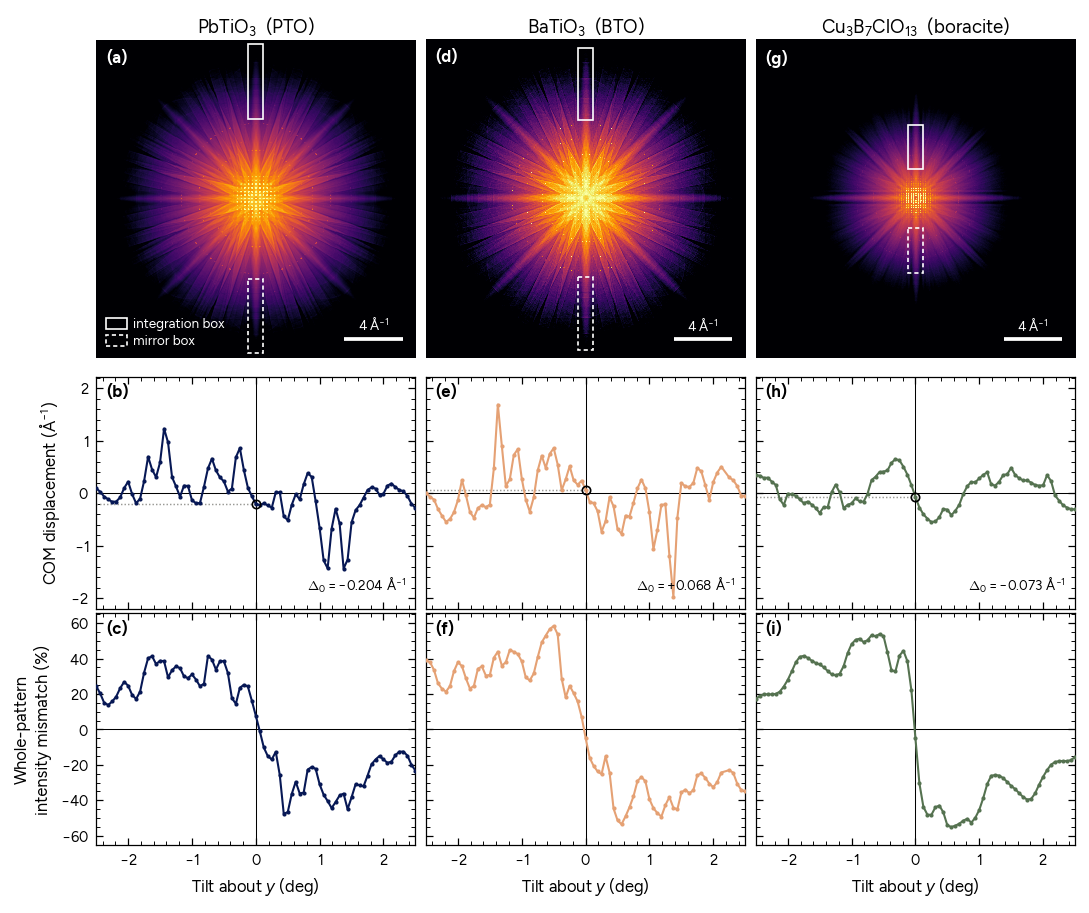

In [5]:
long_range_figure(raw=True)

### Correctly oriented version
What the sims would give had every structure been polarised the same way along the measured
axis (as PTO, +x). From `polarisation_direction.py`: BTO and boracite were simulated with P
reversed relative to PTO (lab P_x = +38.2, -17.9, -0.71 uC/cm2), so both are mirrored,
y(t) -> -y(-t); PTO is unchanged. Tilt axis uses the same `TILT_SIGN` convention as the main
figure. Differs from the main figure only in boracite. Saved with the `aligned_` prefix.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved figures/aligned_kikuchi_long_range.{pdf,png}


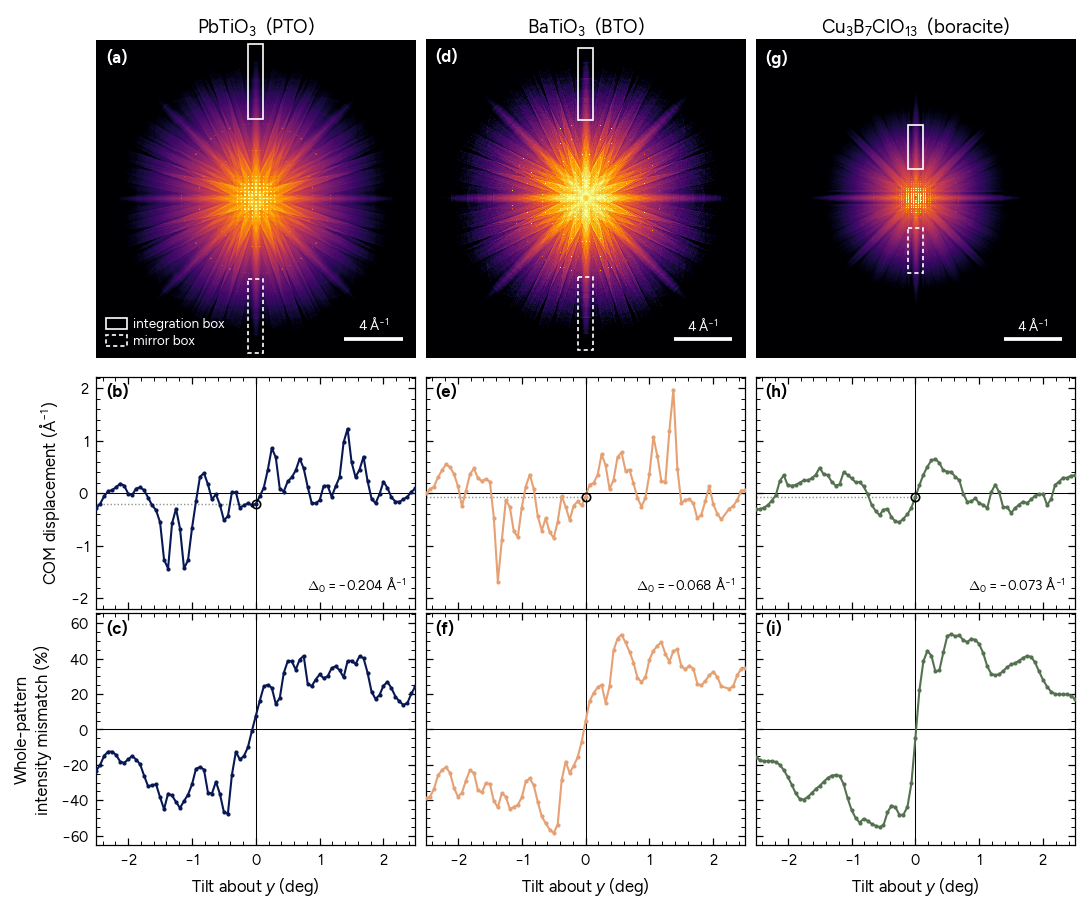

In [6]:
long_range_figure(aligned=True)

**Reading the figure.** Row (a)–(c): simulated CBED pattern at zero tilt, log intensity,
with the integration box and its mirror. Row (d)–(f): corrected centre-of-mass displacement
along the polar axis. Row (g)–(i): whole-pattern intensity mismatch between the two halves.

The polarisation signature is the part of the curve that does **not** invert when the tilt is
reversed. Columns share y-limits, so the three materials are directly comparable.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved figures/corrected_final/corrected_final_kikuchi_long_range.{pdf,png}


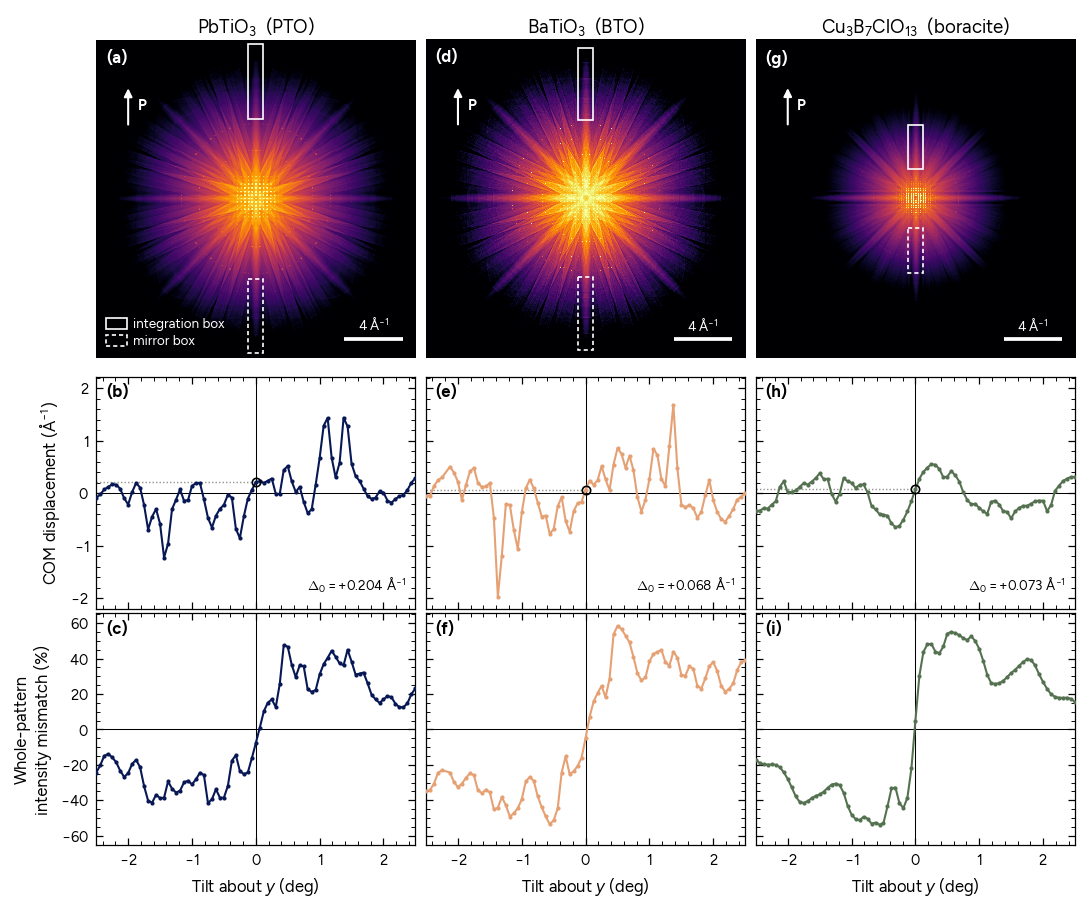

In [7]:
long_range_figure(final=True)